# Week 6: Fairness Mitigation and the Disparate Treatment Tension

<sub>[Previous: Deep-Learning Benchmark and Model Selection](week5_01_deep_learning_and_selection.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 5 selected XGBoost as the primary model. The week-4 fairness audit showed that NH Black mothers receive disproportionately high risk flags while NH Asian mothers are under-flagged relative to NH White mothers, a gap measured by unequal true-positive rates (equal opportunity). This week we ask: can algorithmic mitigation close that gap, and at what cost? The answer reveals a deep tension between disparate treatment (using race-aware thresholds) and disparate impact (leaving unequal outcomes untouched).

As throughout this project, nothing here is a clinical tool: these are associational patterns in administrative data, not statements about any individual. This week shows group-specific thresholds as an analytical exercise, so the caveat matters more here than anywhere else. Race is treated as a marker of exposure to structural racism, never as a biological cause.

### Contents

1. [Setup: load mitigation results](#setup)
2. [The problem: unequal opportunity across groups](#problem)
3. [The three levers: pre-, in-, and post-processing](#three-levers)
4. [Results: what mitigation buys and what it costs](#tradeoffs)
5. [Disparate treatment vs. disparate impact](#treatment-vs-impact)
6. [The road ahead (weeks 7 through 9)](#plan)

<a id="setup"></a>
## Setup: load mitigation results

All mitigation experiments were run by `scripts/week6_mitigation.py`. We read the summary JSON here. The reference group is NH White; all EO gaps are measured as the difference in true-positive rate (sensitivity) between a given group and the reference.

In [1]:
# Week 6 reads back the fairness mitigation results from
# reports/week6_mitigation.json (produced by scripts/week6_mitigation.py).
# The heavy computation happened in a script; the notebook reports and interprets the results.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RNG = 7

REPORTS = Path("..") / "reports"
M = json.loads((REPORTS / "week6_mitigation.json").read_text())
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax

# Self-contained: load a slim projection of the modeling working set.
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)


A few rows from the leakage-safe feature matrix, for orientation:

In [2]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care
0,1,held_out_final,NH White,33.0,3,20.400000,0,0,1
1,0,held_out_final,Hispanic,21.0,3,35.900002,0,0,0
2,0,held_out_final,NH Asian,38.0,7,18.900000,0,0,1
3,0,held_out_final,NH White,30.0,3,24.400000,0,0,1
4,0,dev_train,NH White,31.0,8,19.600000,0,0,1


In [3]:
mit = M['mitigations']
print(f"Fairness subsample: {M['fairness_subsample_n']:,} births")
print(f"Threshold (Youden-optimal on validation): {M['threshold']:.5f}")
print(f"Reference group: {M['reference_group']}")
print(f"Comparison groups: {M['groups']}")
print(f"Seed: {M['seed']}")

Fairness subsample: 100,000 births
Threshold (Youden-optimal on validation): 0.07839
Reference group: NH White
Comparison groups: ['Hispanic', 'NH AIAN', 'NH Asian', 'NH Black', 'NH Multiracial', 'NH NHOPI']
Seed: 42


<a id="problem"></a>
## The problem: unequal opportunity across groups

Equal opportunity (Hardt, Price, and Srebro, 2016; [arXiv:1610.02413](https://arxiv.org/abs/1610.02413)) requires that a classifier's true-positive rate be the same across protected groups. In a preterm-birth screener, violating EO means that some groups of mothers who *will* deliver preterm are less likely to be flagged for early intervention than others, holding outcome constant.

The baseline XGBoost model (week-4 tuned, isotonic-calibrated) produces the following EO gaps relative to NH White:

In [4]:
print(f"{'Group':<20}{'EO gap (TPR - ref)':>20}")
print('-' * 40)
for grp, gap in mit['baseline']['per_group_eo_gap'].items():
    print(f"{grp:<20}{gap:>+20.4f}")
print()
print(f"Worst-group EO gap: {mit['baseline']['worst_group_eo_gap']:.4f}")
print(f"Mean |EO gap|:      {mit['baseline']['mean_abs_eo_gap']:.4f}")

Group                 EO gap (TPR - ref)
----------------------------------------
Hispanic                         +0.0843
NH AIAN                          +0.2504
NH Asian                         -0.0145
NH Black                         +0.3893
NH Multiracial                   +0.0464
NH NHOPI                         +0.0496

Worst-group EO gap: 0.3893
Mean |EO gap|:      0.1391


NH Black mothers have a positive gap of ~0.39, meaning the baseline model is 39 percentage points *more* sensitive for NH Black mothers than for NH White mothers at the same threshold. This is *not* the direction the clinical equity concern usually runs (that would be under-detection). Here the model over-flags Black mothers at a fixed threshold because their base rate is higher and the calibrated scores are shifted right. NH AIAN mothers show a +0.25 gap for the same structural reason.

The implication: at a single universal threshold, the model treats groups unequally because of base-rate differences that reflect upstream structural inequity (access to prenatal care, chronic-stress burden, socioeconomic stratification). The question is whether algorithmic post-processing can equalize opportunity without destroying the model's predictive utility.

<a id="three-levers"></a>
## The three levers: pre-, in-, and post-processing

The fairness-ML literature (Barocas, Hardt, and Narayanan, [Fairness and Machine Learning](https://fairmlbook.org/), 2023) organizes mitigation into three families:

**Pre-processing** modifies the training data before the model sees it. The simplest version is *reweighting*: assign each training instance a weight inversely proportional to its group-by-outcome cell frequency, so that the model sees an effectively balanced joint distribution of group membership and label. This approach does not touch the model architecture or decision rule. It is race-aware at training time (the weights depend on group labels) but produces a single universal model that makes predictions without consulting group membership at inference.

**In-processing** imposes fairness constraints during optimization. Fairlearn's `ExponentiatedGradient` (Agarwal et al., 2018) treats the fairness constraint as a player in a zero-sum game against the loss minimizer. The algorithm iteratively reweights training instances to steer the learner toward a model that satisfies a specified constraint (here, TPR parity across groups). The base learner is a logistic regression, because ExponentiatedGradient requires a cost-sensitive learner that accepts sample weights. The result is a hard classifier; no well-calibrated probabilities are available, so AUC-PR is not computable.

**Post-processing** adjusts the decision rule after the model is trained. Fairlearn's `ThresholdOptimizer` finds group-specific thresholds that equalize TPR across groups. It takes the baseline model's predicted probabilities and selects a different operating point for each group. This is the most direct route to EO parity: by definition, you can always find thresholds that equalize TPR. The cost is that different groups face different decision rules, which is the textbook definition of *disparate treatment*.

<a id="tradeoffs"></a>
## Results: what mitigation buys and what it costs

We compare four approaches: the baseline (no mitigation), reweighting (pre-processing), ExponentiatedGradient (in-processing), and ThresholdOptimizer (post-processing). The table below shows summary-level performance and fairness metrics for each.

In [5]:
# Summary metrics table
methods = ['baseline', 'reweight', 'expgrad', 'threshopt']
labels = ['Baseline (XGB)', 'Reweight', 'ExpGrad', 'ThreshOpt']

print(f"{'Method':<18}{'Sensitivity':>12}{'Specificity':>13}{'Worst EO gap':>14}{'Mean |EO|':>12}")
print('-' * 69)
for meth, lbl in zip(methods, labels):
    d = mit[meth]
    sens = d['sensitivity']
    spec = d['specificity']
    wg = d['worst_group_eo_gap']
    mg = d['mean_abs_eo_gap']
    print(f"{lbl:<18}{sens:>12.4f}{spec:>13.4f}{wg:>14.4f}{mg:>12.4f}")

print()
print('Note: ExpGrad uses a logistic base learner (hard 0/1); no AUC-PR available.')
print('Note: ThreshOpt uses group-specific thresholds (disparate treatment).')

Method             Sensitivity  Specificity  Worst EO gap   Mean |EO|
---------------------------------------------------------------------
Baseline (XGB)          0.6068       0.6062        0.3893      0.1391
Reweight                0.6093       0.5863        0.5042      0.1147
ExpGrad                 0.0098       0.9986        0.0720      0.0178
ThreshOpt               0.5019       0.7010        0.1729      0.0557

Note: ExpGrad uses a logistic base learner (hard 0/1); no AUC-PR available.
Note: ThreshOpt uses group-specific thresholds (disparate treatment).


In [6]:
# AUC-PR and AUC-ROC for the two methods that produce probabilities.
# Report BOTH equal-width ECE and the stricter equal-mass (quantile) ECE.
print(f"{'Method':<18}{'AUC-PR':>10}{'AUC-ROC':>10}{'ECE (width)':>14}{'ECE (quantile)':>16}")
print('-' * 68)
for meth, lbl in [('baseline', 'Baseline'), ('reweight', 'Reweight')]:
    d = mit[meth]
    print(f"{lbl:<18}{d['auc_pr']:>10.5f}{d['auc_roc']:>10.4f}"
          f"{d['ece']:>14.7f}{d['ece_quantile']:>16.7f}")

Method                AUC-PR   AUC-ROC   ECE (width)  ECE (quantile)
--------------------------------------------------------------------
Baseline             0.17229    0.6563     0.0007021       0.0025900
Reweight             0.16564    0.6430     0.0003802       0.0015412


**A note on the ECE numbers.** The equal-width ECE looks almost too good. That is partly a binning artifact: at an 8.6% base rate the predictions cluster in the low-probability bins, so most equal-width bins are nearly empty and contribute little error. The stricter equal-mass (quantile) ECE, which puts an equal number of predictions in each bin, is the more honest read and is reported alongside it above. Both are small, but the quantile version is the one to trust.

**Key observations:**

- **Reweighting** trades a little discrimination (AUC-PR drops, shown above) for a large improvement on the group it has mass to learn from and a destabilization of a tiny one. It substantially shrinks the NH Black equal-opportunity gap, which is the largest group and the one that dominated the baseline disparity, but it worsens NH NHOPI, a very small and noisy group where the reweighting mass is thin. The next cell shows this directly.
- **ExponentiatedGradient** reaches the tightest EO gaps of any method, but its near-zero mitigated sensitivity is a setup artifact, not a fairness cost. The cell below unpacks why.
- **ThresholdOptimizer** offers a middle ground: moderate EO reduction while retaining meaningful sensitivity (values in the summary table above). But it does so by applying different thresholds to different racial groups, which is disparate treatment.

In [7]:
# Reweighting: helps the large group, destabilizes the tiny one.
bl = mit['baseline']['per_group_eo_gap']
rw = mit['reweight']['per_group_eo_gap']
for g in ['NH Black', 'NH NHOPI']:
    print(f"{g:<10} EO gap  baseline {bl[g]:+.4f}  ->  reweight {rw[g]:+.4f}  "
          f"(|gap| {'shrinks' if abs(rw[g]) < abs(bl[g]) else 'grows'})")
print()
print(f"Mean |EO gap|  baseline {mit['baseline']['mean_abs_eo_gap']:.4f}  ->  "
      f"reweight {mit['reweight']['mean_abs_eo_gap']:.4f}")
print(f"Worst |EO gap| baseline {mit['baseline']['worst_group_eo_gap']:.4f}  ->  "
      f"reweight {mit['reweight']['worst_group_eo_gap']:.4f} (driven by the tiny NH NHOPI group)")

NH Black   EO gap  baseline +0.3893  ->  reweight +0.0174  (|gap| shrinks)
NH NHOPI   EO gap  baseline +0.0496  ->  reweight -0.5042  (|gap| grows)

Mean |EO gap|  baseline 0.1391  ->  reweight 0.1147
Worst |EO gap| baseline 0.3893  ->  reweight 0.5042 (driven by the tiny NH NHOPI group)


So reweighting is not a failure and not a free win. It moves mass toward equalizing the group-by-outcome cells, which helps the large NH Black group it can actually learn from, while the smallest group (NH NHOPI) has too few births for that reweighting to be stable and its gap swings the other way. This is the honest shape of pre-processing on a long-tailed group distribution: it helps where there is data and destabilizes where there is not.

In [8]:
# ExpGrad's near-zero sensitivity is an operating-point artifact, not a fairness cost.
eg = mit['expgrad']
base_sens = eg['expgrad_baseline_sens']
xgb_sens = mit['baseline']['sensitivity']
xgb_thr = mit['baseline']['threshold']
print(f"ExpGrad UNCONSTRAINED logistic baseline sensitivity (at 0.5 cutoff): {base_sens:.4f}")
print(f"ExpGrad CONSTRAINED sensitivity (at 0.5 cutoff):                     {eg['sensitivity']:.4f}")
print(f"XGBoost baseline sensitivity (at tuned {xgb_thr:.3f} threshold):          {xgb_sens:.4f}")
print()
print(f"ExpGrad worst-group EO gap: {eg['worst_group_eo_gap']:.4f}  "
      f"mean |EO gap|: {eg['mean_abs_eo_gap']:.4f}")

ExpGrad UNCONSTRAINED logistic baseline sensitivity (at 0.5 cutoff): 0.0089
ExpGrad CONSTRAINED sensitivity (at 0.5 cutoff):                     0.0098
XGBoost baseline sensitivity (at tuned 0.078 threshold):          0.6068

ExpGrad worst-group EO gap: 0.0720  mean |EO gap|: 0.0178


**Reading the ExpGrad result correctly.** It is tempting to say the fairness constraint crushed sensitivity to near zero. That reading is wrong. The *unconstrained* logistic baseline already sits at roughly the same near-zero sensitivity (printed above), because the classifier is evaluated at the default 0.5 decision cutoff and at an 8.6% prevalence almost no logistic score ever exceeds 0.5. The XGBoost baseline looks far more sensitive only because it is scored at a tuned threshold near 0.078, not 0.5. So the two are being compared at incomparable operating points, and the near-zero number is an artifact of the 0.5 cutoff on a weak convex learner, not a price paid for the TPR-parity constraint.

What ExponentiatedGradient genuinely achieved is real and worth stating: near-complete TPR equalization (the tightest worst-group gap of any method here) using only a logistic base learner. The lesson is that the in-processing machinery works; the logistic base learner and the default cutoff, not the fairness constraint, are what make the raw sensitivity look bad.

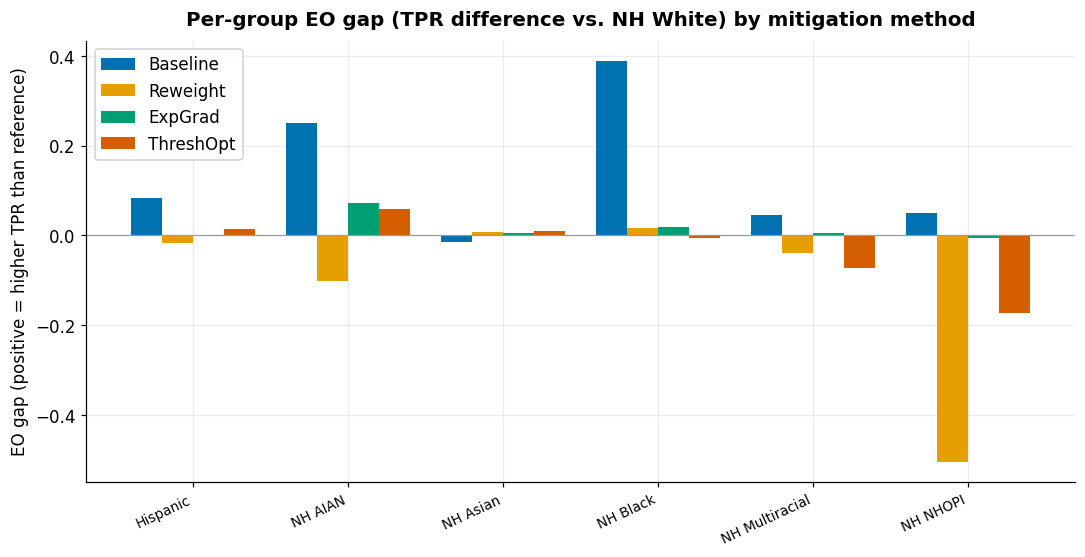

In [9]:
# Grouped bar chart: per-group EO gaps by mitigation method
groups = M['groups']
methods = ['baseline', 'reweight', 'expgrad', 'threshopt']
method_labels = ['Baseline', 'Reweight', 'ExpGrad', 'ThreshOpt']
colors = [PALETTE['blue'], PALETTE['orange'], PALETTE['green'], PALETTE['red']]

x = np.arange(len(groups))
width = 0.20

fig, ax = plt.subplots(figsize=(10, 5.2))
for i, (meth, lbl, col) in enumerate(zip(methods, method_labels, colors)):
    vals = [mit[meth]['per_group_eo_gap'][g] for g in groups]
    ax.bar(x + i * width, vals, width, label=lbl, color=col, edgecolor='none')

ax.axhline(0, color=PALETTE['grey'], lw=0.8)
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(groups, rotation=25, ha='right', fontsize=9)
ax.legend(loc='upper left', framealpha=0.9)
style(ax, 'Per-group EO gap (TPR difference vs. NH White) by mitigation method',
      '', 'EO gap (positive = higher TPR than reference)')
plt.tight_layout(); plt.show()

The chart makes visually clear what the numbers say: ExpGrad drives all gaps toward zero (at the cost of collapsing sensitivity), ThreshOpt moderates the gaps substantially, while reweighting and the baseline show large swings.

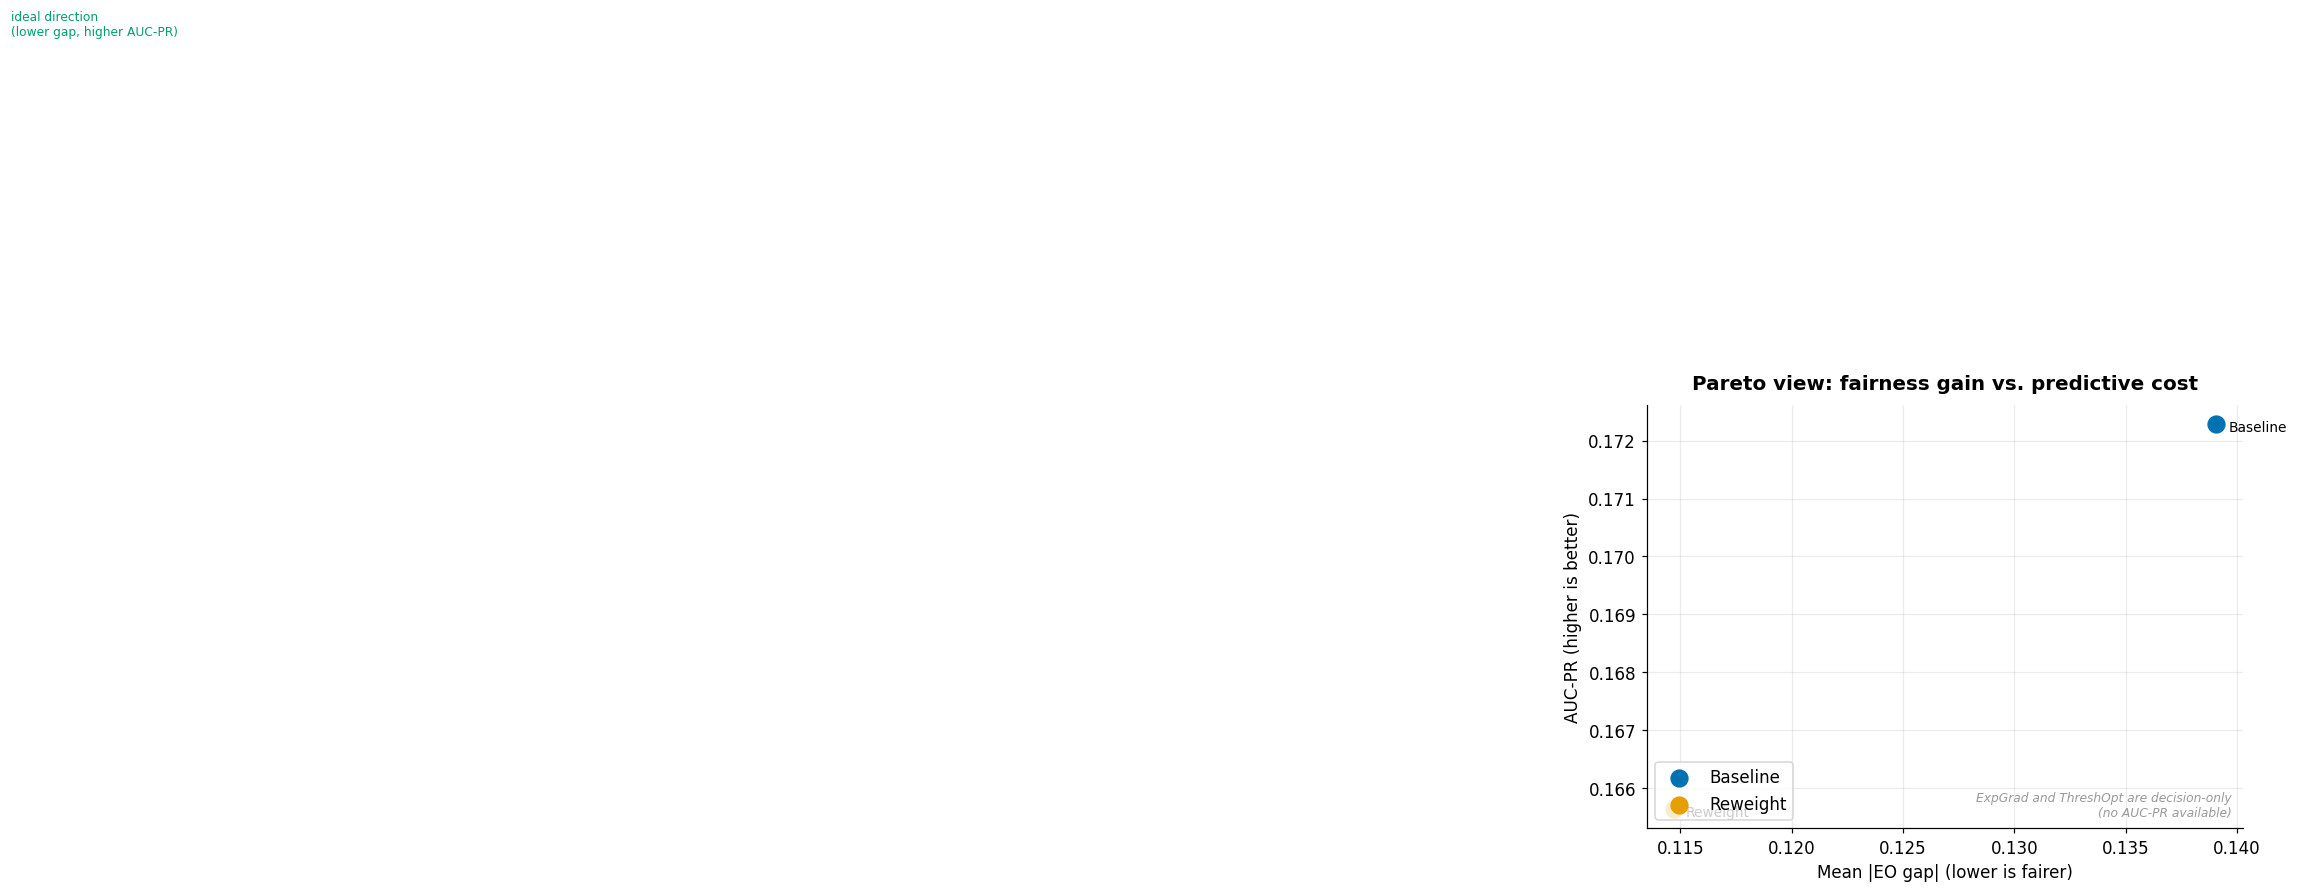

In [10]:
# Pareto scatter: fairness gain vs. AUC-PR cost
# Only baseline and reweight have AUC-PR; ExpGrad and ThreshOpt are decision-only.
fig, ax = plt.subplots(figsize=(7.0, 5.0))

bl_auc = mit['baseline']['auc_pr']
rw_auc = mit['reweight']['auc_pr']
bl_eo = mit['baseline']['mean_abs_eo_gap']
rw_eo = mit['reweight']['mean_abs_eo_gap']

# Plot baseline and reweight
ax.scatter(bl_eo, bl_auc, s=120, color=PALETTE['blue'], zorder=5, label='Baseline')
ax.scatter(rw_eo, rw_auc, s=120, color=PALETTE['orange'], zorder=5, label='Reweight')

# Annotate
ax.annotate('Baseline', (bl_eo, bl_auc), textcoords='offset points',
            xytext=(8, -5), fontsize=9)
ax.annotate('Reweight', (rw_eo, rw_auc), textcoords='offset points',
            xytext=(8, -5), fontsize=9)

# Arrow showing ideal direction
ax.annotate('', xy=(0.02, 0.18), xytext=(0.10, 0.15),
            arrowprops=dict(arrowstyle='->', color=PALETTE['green'], lw=2))
ax.text(0.04, 0.179, 'ideal direction\n(lower gap, higher AUC-PR)',
        fontsize=8, color=PALETTE['green'])

style(ax, 'Pareto view: fairness gain vs. predictive cost',
      'Mean |EO gap| (lower is fairer)', 'AUC-PR (higher is better)')
ax.legend(loc='lower left')

# Note about decision-only methods
ax.text(0.98, 0.02, 'ExpGrad and ThreshOpt are decision-only\n(no AUC-PR available)',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=8,
        style='italic', color=PALETTE['grey'])

plt.tight_layout(); plt.show()

The Pareto scatter shows reweighting moving left on the mean-gap axis (it does reduce the average |EO gap|, driven by the large NH Black group) while paying a real AUC-PR cost. The mean-gap view flatters reweighting: it hides that the *worst*-group gap grew, because the tiny NH NHOPI group swung the other way. There is no free lunch here, and the aggregate fairness number can move the opposite way from the worst-off group.

<a id="treatment-vs-impact"></a>
## Disparate treatment vs. disparate impact

This section is the ethical core of the notebook. The mitigation results reveal a fundamental legal and moral tension:

**Disparate impact** occurs when a facially neutral policy produces unequal outcomes across protected groups. The baseline model uses a single threshold for everyone, but because base rates differ, it flags NH Black mothers at a much higher rate. If the system is used to allocate scarce intervention resources, groups with higher flag rates bear a heavier burden of false positives (unnecessary interventions, surveillance, anxiety).

**Disparate treatment** occurs when a policy explicitly uses group membership to make decisions. The ThresholdOptimizer applies race-specific thresholds: it literally uses a different decision rule depending on the mother's race. This is the textbook definition of disparate treatment, regardless of whether the intent is to help disadvantaged groups.

The legal tension is well-illustrated by *Ricci v. DeStefano* (557 U.S. 557, 2009), in which the U.S. Supreme Court held that an employer cannot engage in intentional race-conscious action (disparate treatment) merely to avoid a disparate-impact outcome, absent a strong basis in evidence that the original practice was actually unlawful. Applied here: one cannot simply deploy race-specific thresholds because the single threshold produces unequal flag rates, unless there is a compelling justification beyond statistical disparity alone.

**What we would never deploy:** The ThresholdOptimizer results are reported here as an analytical exercise to measure the *ceiling* of what post-processing can achieve. The project demo will never expose race-specific thresholds to end users. Any deployed system would use a single universal threshold.

**What we recommend instead:**

1. **Monitoring without race-aware adjustment.** Deploy a single threshold, but continuously track per-group TPR, FPR, and calibration. When gaps exceed a pre-specified tolerance, flag the disparity for human review rather than automatically adjusting.

2. **Upstream structural interventions.** The EO gap exists because the features themselves reflect structural inequity (differential access to prenatal care, chronic stress, socioeconomic stratification). The responsible response is not to paper over the gap at the scoring layer but to address it at the data-generation layer: expand access, reduce barriers, and collect richer contextual variables that explain rather than merely encode race.

3. **Transparent reporting.** Publish per-group performance alongside overall metrics so that stakeholders can make informed decisions about acceptable tradeoffs. The SHAP decomposition in week 7 will quantify how much of the racial gap in predicted risk is attributable to medical factors vs. socioeconomic proxies.

<a id="plan"></a>
## The road ahead (weeks 7 through 9)

The model is selected and the mitigation landscape is mapped. The remaining work turns from *what can we do about the gap* to *what does the gap mean*.

**Week 7: SHAP and disparity decomposition.** TreeSHAP on the selected model, stratified by race. Decompose the racial gap in predicted risk into feature-group contributions (medical risk, SES, access, behavioral). Quantify how much of the observed disparity the measured factors account for.

**Week 8: Robustness and drift.** Out-of-time validation across birth-year eras (pre-COVID, COVID, post-COVID). Stability of calibration and fairness metrics over time. Sensitivity to feature perturbation.

**Week 9: Transparency report and demo.** A self-contained summary of findings, limitations, and recommendations. An interactive prototype (Streamlit or similar) for exploring risk scores and disparity decompositions.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
